In [1]:
from pathlib import Path

In [2]:
import sys
import pandas as pd

In [3]:
print(sys.executable)

/Users/prathmmsh/Documents/Coding/Environments/shared/bin/python


In [4]:
project = Path.cwd()

if not (project / "data/raw/online_retail_II.xlsx").exists():
    project = project / "DS5020-MiniProject"

data_path = project / "data/raw/online_retail_II.xlsx"

assert data_path.exists(), (
    "Place online_retail_II.xlsx in the repository's data/raw/ folder "
    "and run the notebook from the repository or its parent folder."
)

print("Dataset found:", data_path.exists())

Dataset found: True


In [5]:
print(data_path.exists())

True


In [6]:
sheets = pd.read_excel(data_path, sheet_name=None, engine="openpyxl")
for name, sheet in sheets.items():
    print(f"{name}: {len(sheet):,} rows")

Year 2009-2010: 525,461 rows
Year 2010-2011: 541,910 rows


In [7]:
df = pd.concat(sheets.values(), ignore_index=True)

In [8]:
print(f"Total Rows: {len(df):,}")
print("Columns:", df.columns.tolist())

Total Rows: 1,067,371
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [9]:
profile = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

In [10]:
display(profile)

print("Earliest Invoice:",
      df["InvoiceDate"].min())
print("Latest Invoice:",
      df["InvoiceDate"].max())

,Data type,Missing values,Missing (%)
Invoice,object,0,0.00
StockCode,object,0,0.00
Description,object,4382,0.41
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
Price,float64,0,0.00
Customer ID,float64,243007,22.77
Country,str,0,0.00


Earliest Invoice: 2009-12-01 07:45:00
Latest Invoice: 2011-12-09 12:50:00


In [11]:
profile = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

display(profile)

print("Earliest invoice:", df["InvoiceDate"].min())
print("Latest invoice:", df["InvoiceDate"].max())

,Data type,Missing values,Missing (%)
Invoice,object,0,0.00
StockCode,object,0,0.00
Description,object,4382,0.41
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
Price,float64,0,0.00
Customer ID,float64,243007,22.77
Country,str,0,0.00


Earliest invoice: 2009-12-01 07:45:00
Latest invoice: 2011-12-09 12:50:00


In [12]:
issues = pd.Series({
    "Cancelled invoice lines": df["Invoice"].astype(str).str.upper().str.startswith("C").sum(),
    "Non-positive quantities": (df["Quantity"] <= 0).sum(),
    "Non-positive prices": (df["Price"] <= 0).sum(),
    "Missing customer IDs": df["Customer ID"].isna().sum(),
    "Missing descriptions": df["Description"].isna().sum()
})

In [13]:
display(issues)

Cancelled invoice lines     19494
Non-positive quantities     22950
Non-positive prices          6207
Missing customer IDs       243007
Missing descriptions         4382
dtype: int64

In [14]:
codes = df["StockCode"].astype(str).str.upper().str.strip()
unusual = df.loc[
    ~codes.str.match(r"^\d{5}[A-Z]*$"),
    ["StockCode", "Description"]
]

In [15]:
display(
    unusual.groupby(["StockCode", "Description"], dropna = False)
    .size()
    .reset_index(name = "Line Cnt")
    .sort_values("Line Cnt", ascending = False)
    .head(30)
)

,StockCode,Description,Line Cnt
66,POST,POSTAGE,2115
61,DOT,DOTCOM POSTAGE,1444
64,M,Manual,1421
8,C2,CARRIAGE,279
12,D,Discount,177
68,S,SAMPLES,104
7,BANK CHARGES,Bank Charges,96
4,AMAZONFEE,AMAZON FEE,43
1,ADJUST,Adjustment by john on 26/01/2010 16,38
30,DCGS0058,MISO PRETTY GUM,30


In [16]:
clean = df.copy()
clean["StockCode"] = (
    clean["StockCode"].astype(str).str.strip().str.upper()
)

cleaning_log = []

def remove_rows(reason, mask):
    global clean
    before = len(clean)
    clean = clean.loc[~mask].copy()
    cleaning_log.append({
        "Rule": reason,
        "Removed": before - len(clean),
        "Remaining": len(clean)
    })

remove_rows(
    "Cancelled Invoices",
    clean["Invoice"]
    .astype(str).str.upper().str.startswith("C")
)

remove_rows(
    "None-positive Quantities", clean["Quantity"] <= 0
)
remove_rows(
    "None-positive Prices", clean["Price"] <= 0
)
remove_rows(
    "Missing Customer IDs", clean["Customer ID"].isna()
)

non_products = {
    "POST", "DOT", "M", "C2", "D", "S",
    "BANK CHARGES",
    "AMAZONFEE",
    "ADJUST",
    "ADJUST2",
    "CRUK",
    "B",
    "TEST001"
}

remove_rows(
    "Charges, Adjustments, samples, tests & gift vouchers",
    clean["StockCode"].isin(non_products)
    | clean["StockCode"].str.startswith("Gift_")
)

display(pd.DataFrame(cleaning_log))

,Rule,Removed,Remaining
0,Cancelled Invoices,19494,1047877
1,None-positive Quantities,3457,1044420
2,None-positive Prices,2750,1041670
3,Missing Customer IDs,236121,805549
4,"Charges, Adjustments, samples, tests & gift vo...",2897,802652


In [17]:
clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"])

end_exclusive = (
    clean["InvoiceDate"]
    .max()
    .normalize()
    +pd.Timedelta(days=1)
)
cutoff = end_exclusive - pd.DateOffset(months=2)

train = clean.loc[clean["InvoiceDate"] < cutoff].copy()
test = clean.loc[clean["InvoiceDate"] >= cutoff].copy()

In [18]:
print("Test Starts:", cutoff)
print(f"Training lines: {len(train):,}")
print(f"Test lines: {len(test):,}")

Test Starts: 2011-10-10 00:00:00
Training lines: 684,931
Test lines: 117,721


In [19]:
assert len(train) + len(test) == len(clean)
assert train["InvoiceDate"].max() < test["InvoiceDate"].min()

In [20]:
pair_columns = ["Customer ID", "StockCode"]

train_pairs = train[pair_columns].drop_duplicates()
test_pairs = test[pair_columns].drop_duplicates()

comparison = test_pairs.merge(
    train_pairs,
    on=pair_columns,
    how="left",
    indicator=True
)

new_test_pairs = (
    comparison.loc[comparison["_merge"] == "left_only", pair_columns]
    .copy()
)


In [21]:
print(f"Unique test customer-product pairs: {len(test_pairs):,}")
print(f"New-to-customer test pairs: {len(new_test_pairs):,}")
print(f"Customers with new purchases: {new_test_pairs['Customer ID'].nunique():,}")

Unique test customer-product pairs: 94,306
New-to-customer test pairs: 62,625
Customers with new purchases: 2,296


In [22]:
product_support = train.groupby("StockCode")["Customer ID"].nunique()

kept_products = product_support[product_support >= 10].index

train_model = train.loc[
    train["StockCode"].isin(kept_products)
].copy()

In [23]:
print(f"Products before filtering: {train['StockCode'].nunique():,}")
print(f"Products retained: {len(kept_products):,}")
print(f"Training lines retained: {len(train_model):,}")

Products before filtering: 4,533
Products retained: 3,690
Training lines retained: 680,565


In [24]:
import numpy as np
import scipy.sparse as sp

In [25]:
purchase = (
    train_model.groupby(["Customer ID", "StockCode"]) ["Quantity"]
    .sum()
    .reset_index()

)

customers = sorted(train_model["Customer ID"].unique())
products = sorted(train_model["StockCode"].unique())

cust = {customer: i for i, customer in enumerate(customers)}
prod = {product: j for j, product in enumerate(products)}

rows = purchase["Customer ID"].map(cust).to_numpy()
cols = purchase["StockCode"].map(prod).to_numpy()

values = np.log(purchase["Quantity"].to_numpy(dtype = float))

A = sp.csr_matrix(
    (values, (rows, cols)),
    shape = (len(customers), len(products))
)

In [26]:
print("Matrix shape:", A.shape)
print(f"Non-zero entries: {A.nnz:,}")
print(f"Sparsity: {1 - A.nnz / (A.shape[0] * A.shape[1]):.2%}")

Matrix shape: (5482, 3690)
Non-zero entries: 414,566
Sparsity: 97.95%


In [27]:
dense_byts = A.shape[0] * A.shape[1] * A.dtype.itemsize
sparse_byts = A.data.nbytes + A.indices.nbytes + A.indptr.nbytes

matrix_rep = pd.Series({
    "Customers": A.shape[0],
    "Products": A.shape[1],
    "Non-zero entries": A.nnz,
    "Sparsity": 100 * (1 - A.nnz / (A.shape[0] * A.shape[1])),
    "Dense storage (MB)": dense_byts / 1_000_000,
    "Sparse storage (MB)": sparse_byts / 1_000_000
})

In [28]:
display(matrix_rep)

Customers                5482.000000
Products                 3690.000000
Non-zero entries       414566.000000
Sparsity                   97.950593
Dense storage (MB)        161.828640
Sparse storage (MB)         4.996724
dtype: float64

In [29]:
import time
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

k=10: error=0.8757, time=0.04s
k=20: error=0.8445, time=0.04s
k=50: error=0.7863, time=0.07s
k=100: error=0.7223, time=0.12s
k=200: error=0.6311, time=0.24s


,k,Relative reconstruction error,Fit time (seconds),Factor storage (MB)
0,10,0.875734,0.040617,0.73376
1,20,0.844478,0.043377,1.46752
2,50,0.786307,0.070615,3.66880
3,100,0.722263,0.124682,7.33760
4,200,0.631143,0.235759,14.67520


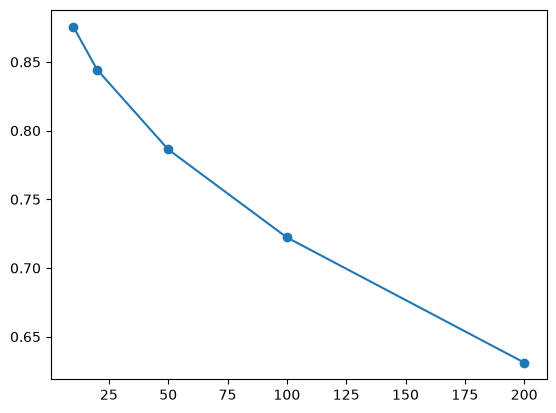

In [30]:
k_values = [10, 20, 50, 100, 200]
svd_results = []
svd_models = {}

total_squared = float(A.multiply(A).sum())

for k in k_values:
    start = time.perf_counter()

    model = TruncatedSVD(n_components=k, random_state=42)
    scores = model.fit_transform(A)

    fit_seconds = time.perf_counter() - start

    captured_squared = float(np.sum(scores ** 2))
    error = np.sqrt(
        max(total_squared - captured_squared, 0) / total_squared
    )

    factor_bytes = scores.nbytes + model.components_.nbytes

    svd_models[k] = model
    svd_results.append({
        "k": k,
        "Relative reconstruction error": error,
        "Fit time (seconds)": fit_seconds,
        "Factor storage (MB)": factor_bytes / 1_000_000
    })

    print(f"k={k}: error={error:.4f}, time={fit_seconds:.2f}s")

svd_results = pd.DataFrame(svd_results)
display(svd_results)

plt.plot(
    svd_results["k"],
    svd_results["Relative reconstruction error"],
    marker="o"
)

In [31]:
chosen_k = 50
svd = svd_models[chosen_k]

from sklearn.preprocessing import normalize

product_vectors = normalize(svd.components_.T)

def similar_products(product_code, n=10):
    j = prod[product_code]
    similarities = product_vectors @ product_vectors[j]
    similarities[j] = -np.inf

    top = np.argsort(-similarities)[:n]

    return pd.DataFrame({
        "StockCode": [products[i] for i in top],
        "Cosine similarity": similarities[top]
    })

display(similar_products(products[0]))

,StockCode,Cosine similarity
0,20704,0.524493
1,21731,0.504045
2,35004B,0.498645
3,85164B,0.498179
4,84796B,0.492817
5,21144,0.491558
6,18007,0.489341
7,79191C,0.474107
8,84932B,0.473072
9,21881,0.470845


In [32]:
def recommend_customer(customer_id, n=10):
    i = cust[customer_id]
    history = A.getrow(i)

    # Weighted sum of the customer's purchased product vectors.
    preference = np.asarray(history @ product_vectors).ravel()
    scores = product_vectors @ preference

    # Never recommend products already purchased.
    scores[history.indices] = -np.inf

    available = np.flatnonzero(np.isfinite(scores))
    top = available[np.argsort(-scores[available])[:n]]

    return pd.DataFrame({
        "StockCode": [products[j] for j in top],
        "Score": scores[top]
    })


In [33]:

display(recommend_customer(customers[0]))

,StockCode,Score
0,23167,10.880262
1,23165,10.869291
2,23299,7.182977
3,23360,7.107366
4,23198,6.586260
5,23197,6.436936
6,22978,6.318538
7,22654,6.172406
8,23436,5.949148
9,22990,5.905840


In [34]:
eligible_test = new_test_pairs.loc[
    new_test_pairs["Customer ID"].isin(cust)
    & new_test_pairs["StockCode"].isin(prod)
].copy()

test_targets = (
    eligible_test.groupby("Customer ID")["StockCode"]
    .agg(set)
    .to_dict()
)

coverage = pd.Series({
    "All new-to-customer test pairs": len(new_test_pairs),
    "Eligible test pairs": len(eligible_test),
    "Pair coverage (%)": 100 * len(eligible_test) / len(new_test_pairs),
    "Customers with new test purchases":
        new_test_pairs["Customer ID"].nunique(),
    "Evaluated customers": len(test_targets)
})

display(coverage)

All new-to-customer test pairs       62625.000000
Eligible test pairs                  44744.000000
Pair coverage (%)                       71.447505
Customers with new test purchases     2296.000000
Evaluated customers                   1910.000000
dtype: float64

In [35]:
best_sellers = (
    train_model.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

def recommend_baseline(customer_id, n=10):
    history = A.getrow(cust[customer_id])
    seen = {products[j] for j in history.indices}

    return [p for p in best_sellers if p not in seen][:n]

svd_hits = 0
baseline_hits = 0

start = time.perf_counter()

for customer_id, targets in test_targets.items():
    recommendations = set(
        recommend_customer(customer_id)["StockCode"]
    )
    svd_hits += bool(recommendations & targets)

svd_eval_seconds = time.perf_counter() - start

start = time.perf_counter()

for customer_id, targets in test_targets.items():
    recommendations = set(recommend_baseline(customer_id))
    baseline_hits += bool(recommendations & targets)

baseline_eval_seconds = time.perf_counter() - start

evaluation = pd.DataFrame({
    "Method": ["SVD", "Best sellers"],
    "Evaluated customers": [len(test_targets), len(test_targets)],
    "Customers with a hit": [svd_hits, baseline_hits],
    "Hit rate at 10 (%)": [
        100 * svd_hits / len(test_targets),
        100 * baseline_hits / len(test_targets)
    ],
    "Evaluation time (seconds)": [
        svd_eval_seconds, baseline_eval_seconds
    ]
})


In [36]:

display(evaluation)

,Method,Evaluated customers,Customers with a hit,Hit rate at 10 (%),Evaluation time (seconds)
0,SVD,1910,426,22.303665,0.537846
1,Best sellers,1910,332,17.382199,0.116740


In [37]:
start = time.perf_counter()

customer_recommendations = [
    recommend_customer(customer_id)["StockCode"].tolist()
    for customer_id in customers
]

customer_job_seconds = time.perf_counter() - start

start = time.perf_counter()

product_recommendations = [
    similar_products(product_code)["StockCode"].tolist()
    for product_code in products
]

product_job_seconds = time.perf_counter() - start

nightly_seconds = customer_job_seconds + product_job_seconds


In [38]:

print(f"Customer recommendations: {customer_job_seconds:.2f} seconds")
print(f"Product similarities: {product_job_seconds:.2f} seconds")
print(f"Total recommendation job: {nightly_seconds:.2f} seconds")

Customer recommendations: 1.65 seconds
Product similarities: 0.76 seconds
Total recommendation job: 2.41 seconds


In [39]:
from sklearn.decomposition import PCA

start = time.perf_counter()

pca = PCA(
    n_components=chosen_k,
    svd_solver="arpack",
    random_state=42
)
pca_scores = pca.fit_transform(A)

pca_fit_seconds = time.perf_counter() - start
pca_factor_bytes = (
    pca_scores.nbytes
    + pca.components_.nbytes
    + pca.mean_.nbytes
)

In [40]:
print(f"PCA fit time: {pca_fit_seconds:.2f} seconds")
print(f"PCA stored factors + mean: {pca_factor_bytes / 1_000_000:.2f} MB")
print(f"PCA variance explained: {pca.explained_variance_ratio_.sum():.2%}")

PCA fit time: 0.10 seconds
PCA stored factors + mean: 3.70 MB
PCA variance explained: 35.71%


In [41]:
pca_product_vectors = normalize(pca.components_.T)

def recommend_pca(customer_id, n=10):
    history = A.getrow(cust[customer_id])

    preference = np.asarray(history @ pca_product_vectors).ravel()
    scores = pca_product_vectors @ preference
    scores[history.indices] = -np.inf

    available = np.flatnonzero(np.isfinite(scores))
    top = available[np.argsort(-scores[available])[:n]]

    return {products[j] for j in top}

pca_hits = 0
start = time.perf_counter()

for customer_id, targets in test_targets.items():
    pca_hits += bool(recommend_pca(customer_id) & targets)

pca_eval_seconds = time.perf_counter() - start
pca_hit_rate = 100 * pca_hits / len(test_targets)

In [42]:
print(f"PCA customers with a hit: {pca_hits}")
print(f"PCA hit rate at 10: {pca_hit_rate:.2f}%")
print(f"PCA evaluation time: {pca_eval_seconds:.2f} seconds")

PCA customers with a hit: 425
PCA hit rate at 10: 22.25%
PCA evaluation time: 0.40 seconds


In [43]:
svd_row = svd_results.loc[
    svd_results["k"] == chosen_k
].iloc[0]

comparison_table = pd.DataFrame({
    "Measure": [
        "Components (k)",
        "Fit time (seconds)",
        "Stored factors + required mean (MB)",
        "PCA explained variance (%)",
        "SVD relative reconstruction error",
        "Hit rate at 10 (%)",
        "Best-seller hit rate at 10 (%)"
    ],
    "PCA": [
        chosen_k,
        pca_fit_seconds,
        pca_factor_bytes / 1_000_000,
        100 * pca.explained_variance_ratio_.sum(),
        np.nan,
        pca_hit_rate,
        100 * baseline_hits / len(test_targets)
    ],
    "Truncated SVD": [
        chosen_k,
        svd_row["Fit time (seconds)"],
        svd_row["Factor storage (MB)"],
        np.nan,
        svd_row["Relative reconstruction error"],
        100 * svd_hits / len(test_targets),
        100 * baseline_hits / len(test_targets)
    ]
})

display(comparison_table.round(4))

,Measure,PCA,Truncated SVD
0,Components (k),50.0000,50.0000
1,Fit time (seconds),0.1027,0.0706
2,Stored factors + required mean (MB),3.6983,3.6688
3,PCA explained variance (%),35.7114,NaN
4,SVD relative reconstruction error,NaN,0.7863
5,Hit rate at 10 (%),22.2513,22.3037
6,Best-seller hit rate at 10 (%),17.3822,17.3822


In [44]:
product_names = (
    train_model.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda names: names.value_counts().index[0])
)

def component_products(model):
    weights = model.components_[0]
    top = np.argsort(-np.abs(weights))[:10]

    return pd.DataFrame({
        "StockCode": [products[j] for j in top],
        "Description": [
            product_names.get(products[j], "Unknown") for j in top
        ],
        "Weight": weights[top]
    })

purchase_volume = np.asarray(A.sum(axis=1)).ravel()
svd_scores = svd.transform(A)

print("SVD component 1: strongest product weights")
display(component_products(svd))

print("PCA component 1: strongest product weights")
display(component_products(pca))

print(
    "SVD component 1 correlation with log-purchase volume:",
    round(np.corrcoef(svd_scores[:, 0], purchase_volume)[0, 1], 3)
)
print(
    "PCA component 1 correlation with log-purchase volume:",
    round(np.corrcoef(pca_scores[:, 0], purchase_volume)[0, 1], 3)
)

SVD component 1: strongest product weights


,StockCode,Description,Weight
0,21212,PACK OF 72 RETROSPOT CAKE CASES,0.135535
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.123302
2,85099B,JUMBO BAG RED RETROSPOT,0.112192
3,20725,LUNCH BAG RED RETROSPOT,0.103918
4,84991,60 TEATIME FAIRY CAKE CASES,0.093880
5,84879,ASSORTED COLOUR BIRD ORNAMENT,0.090216
6,21977,PACK OF 60 PINK PAISLEY CAKE CASES,0.087619
7,22382,LUNCH BAG SPACEBOY DESIGN,0.082357
8,21080,SET/20 RED RETROSPOT PAPER NAPKINS,0.081772
9,22384,LUNCH BAG PINK POLKADOT,0.079023


PCA component 1: strongest product weights


,StockCode,Description,Weight
0,21212,PACK OF 72 RETROSPOT CAKE CASES,0.128696
1,85099B,JUMBO BAG RED RETROSPOT,0.110256
2,20725,LUNCH BAG RED RETROSPOT,0.106778
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.094999
4,84991,60 TEATIME FAIRY CAKE CASES,0.089118
5,21977,PACK OF 60 PINK PAISLEY CAKE CASES,0.084644
6,22382,LUNCH BAG SPACEBOY DESIGN,0.084583
7,22384,LUNCH BAG PINK POLKADOT,0.082066
8,20728,LUNCH BAG CARS BLUE,0.080846
9,20727,LUNCH BAG BLACK SKULL.,0.080137


SVD component 1 correlation with log-purchase volume: 0.966
PCA component 1 correlation with log-purchase volume: 0.966


In [45]:
import json
import subprocess
import tempfile

memory_script = """
import json
import resource
import sys
import scipy.sparse as sp
from sklearn.decomposition import PCA, TruncatedSVD

A = sp.load_npz(sys.argv[1])
method = sys.argv[2]
k = int(sys.argv[3])

if method == "PCA":
    model = PCA(n_components=k, svd_solver="arpack", random_state=42)
else:
    model = TruncatedSVD(n_components=k, random_state=42)

scores = model.fit_transform(A)

peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
peak_bytes = peak if sys.platform == "darwin" else peak * 1024

print(json.dumps({"Peak process memory (MB)": peak_bytes / 1_000_000}))
"""

memory_results = {}

with tempfile.TemporaryDirectory() as folder:
    matrix_path = Path(folder) / "matrix.npz"
    sp.save_npz(matrix_path, A)

    for method in ["PCA", "Truncated SVD"]:
        result = subprocess.run(
            [
                sys.executable, "-c", memory_script,
                str(matrix_path), method, str(chosen_k)
            ],
            capture_output=True,
            text=True,
            check=True
        )
        memory_results[method] = json.loads(result.stdout)[
            "Peak process memory (MB)"
        ]

display(pd.Series(memory_results, name="Peak process memory (MB)"))

PCA              202.407936
Truncated SVD    208.371712
Name: Peak process memory (MB), dtype: float64

In [46]:
extra_rows = pd.DataFrame({
    "Measure": [
        "Peak process memory (MB)",
        "Component 1 interpretation"
    ],
    "PCA": [
        memory_results["PCA"],
        "Purchasing activity relative to the average customer"
    ],
    "Truncated SVD": [
        memory_results["Truncated SVD"],
        "Overall purchasing activity"
    ]
})

comparison_complete = pd.concat(
    [comparison_table, extra_rows],
    ignore_index=True
)

display(comparison_complete)

,Measure,PCA,Truncated SVD
0,Components (k),50.0,50.0
1,Fit time (seconds),0.102748,0.070615
2,Stored factors + required mean (MB),3.69832,3.6688
3,PCA explained variance (%),35.7114,NaN
4,SVD relative reconstruction error,NaN,0.786307
5,Hit rate at 10 (%),22.251309,22.303665
6,Best-seller hit rate at 10 (%),17.382199,17.382199
7,Peak process memory (MB),202.407936,208.371712
8,Component 1 interpretation,Purchasing activity relative to the average cu...,Overall purchasing activity


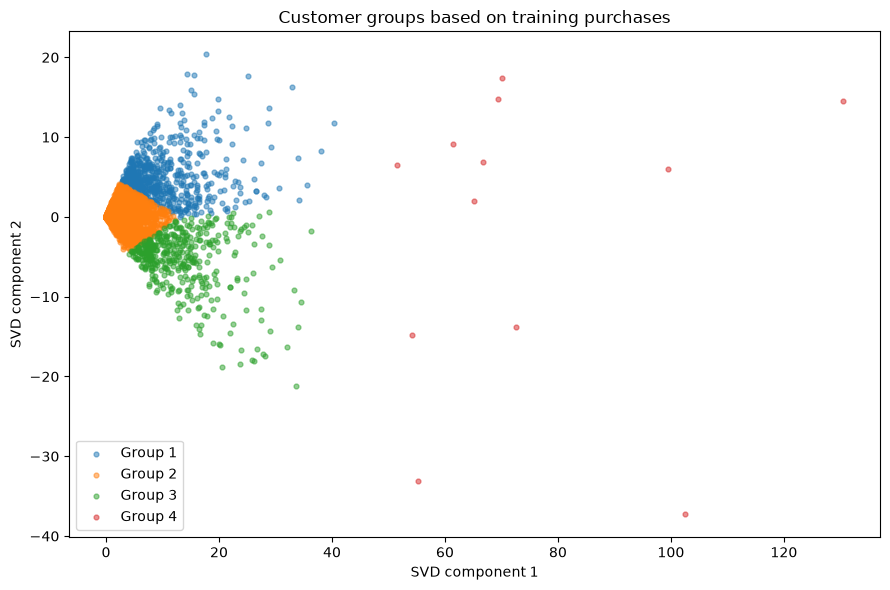

In [47]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

customer_map = svd_scores[:, :2]

map_scaled = StandardScaler().fit_transform(customer_map)

cluster_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)
cluster_labels = cluster_model.fit_predict(map_scaled)

plt.figure(figsize=(9, 6))

for group in range(4):
    mask = cluster_labels == group
    plt.scatter(
        customer_map[mask, 0],
        customer_map[mask, 1],
        s=12,
        alpha=0.5,
        label=f"Group {group + 1}"
    )

plt.xlabel("SVD component 1")
plt.ylabel("SVD component 2")
plt.title("Customer groups based on training purchases")
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
customer_country = (
    train_model.groupby("Customer ID")["Country"]
    .agg(lambda countries: countries.value_counts().index[0])
)

segment_rows = []

for group in range(4):
    indices = np.flatnonzero(cluster_labels == group)
    group_customers = [customers[i] for i in indices]

    # Rank products by number of customers who purchased them.
    buyer_counts = np.asarray(
        (A[indices] > 0).sum(axis=0)
    ).ravel()
    top_products = np.argsort(-buyer_counts)[:5]

    top_countries = (
        customer_country.reindex(group_customers)
        .value_counts()
        .head(3)
    )

    segment_rows.append({
        "Group": group + 1,
        "Customers": len(indices),
        "Average log-purchase activity":
            float(purchase_volume[indices].mean()),
        "Top products": "; ".join(
            product_names.get(products[j], products[j])
            for j in top_products
        ),
        "Top countries": "; ".join(
            f"{country} ({count})"
            for country, count in top_countries.items()
        )
    })

segment_summary = pd.DataFrame(segment_rows)

with pd.option_context("display.max_colwidth", None):
    display(segment_summary)

,Group,Customers,Average log-purchase activity,Top products,Top countries
0,1,605,382.836514,WHITE HANGING HEART T-LIGHT HOLDER; HEART OF WICKER SMALL; ASSORTED COLOUR BIRD ORNAMENT; HEART OF WICKER LARGE; RED HANGING HEART T-LIGHT HOLDER,United Kingdom (589); Cyprus (2); Greece (2)
1,2,4447,75.467225,WHITE HANGING HEART T-LIGHT HOLDER; BAKING SET 9 PIECE RETROSPOT ; REGENCY CAKESTAND 3 TIER; ASSORTED COLOUR BIRD ORNAMENT; PACK OF 72 RETROSPOT CAKE CASES,United Kingdom (4109); Germany (57); France (55)
2,3,418,441.802403,PACK OF 72 RETROSPOT CAKE CASES; LUNCH BAG RED RETROSPOT; LUNCH BAG SPACEBOY DESIGN ; JUMBO BAG RED RETROSPOT; LUNCH BAG CARS BLUE,United Kingdom (300); Germany (38); France (27)
3,4,12,3512.946325,LUNCH BAG APPLE DESIGN; JUMBO BAG PINK POLKADOT; PACK OF 72 RETROSPOT CAKE CASES; SET/20 RED RETROSPOT PAPER NAPKINS ; WALL TIDY RETROSPOT,United Kingdom (8); EIRE (2); Australia (1)


In [49]:
import json

processed = project / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)

sp.save_npz(processed / "purchase_matrix.npz", A)

index_maps = {
    "customers": [str(customer) for customer in customers],
    "products": [str(product) for product in products]
}

with open(processed / "index_maps.json", "w") as file:
    json.dump(index_maps, file, indent=2)

train.to_csv(processed / "train.csv", index=False)
test.to_csv(processed / "test.csv", index=False)
eligible_test.to_csv(processed / "eligible_test_pairs.csv", index=False)

print("Saved matrix, index maps, training data and test data.")

Saved matrix, index maps, training data and test data.


In [50]:
reports = project / "reports"
reports.mkdir(exist_ok=True)

profile.to_csv(reports / "data_profile.csv")

pd.DataFrame(cleaning_log).to_csv(
    reports / "cleaning_log.csv", index=False
)

matrix_rep.to_csv(reports / "matrix_report.csv")

svd_results.to_csv(
    reports / "svd_results.csv", index=False
)

coverage.to_csv(reports / "evaluation_coverage.csv")

evaluation.to_csv(
    reports / "recommendation_evaluation.csv", index=False
)

comparison_complete.to_csv(
    reports / "pca_svd_comparison.csv", index=False
)

segment_summary.to_csv(
    reports / "customer_segments.csv", index=False
)

pd.Series({
    "Customer recommendation time (seconds)": customer_job_seconds,
    "Product similarity time (seconds)": product_job_seconds,
    "Total recommendation time (seconds)": nightly_seconds
}).to_csv(reports / "nightly_runtime.csv")

print("Reports saved in:", reports)

Reports saved in: /Users/prathmmsh/Documents/Coding/DS5020-MiniProject/reports


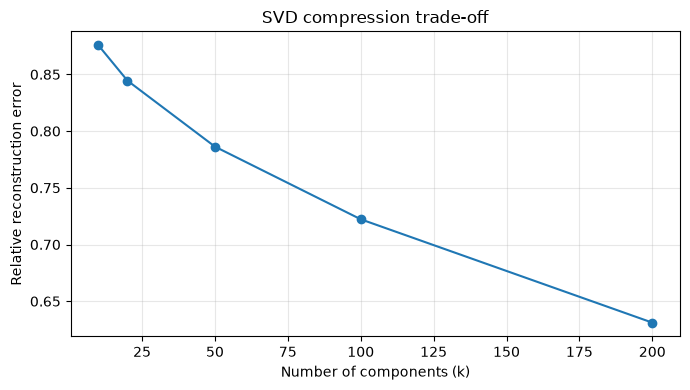

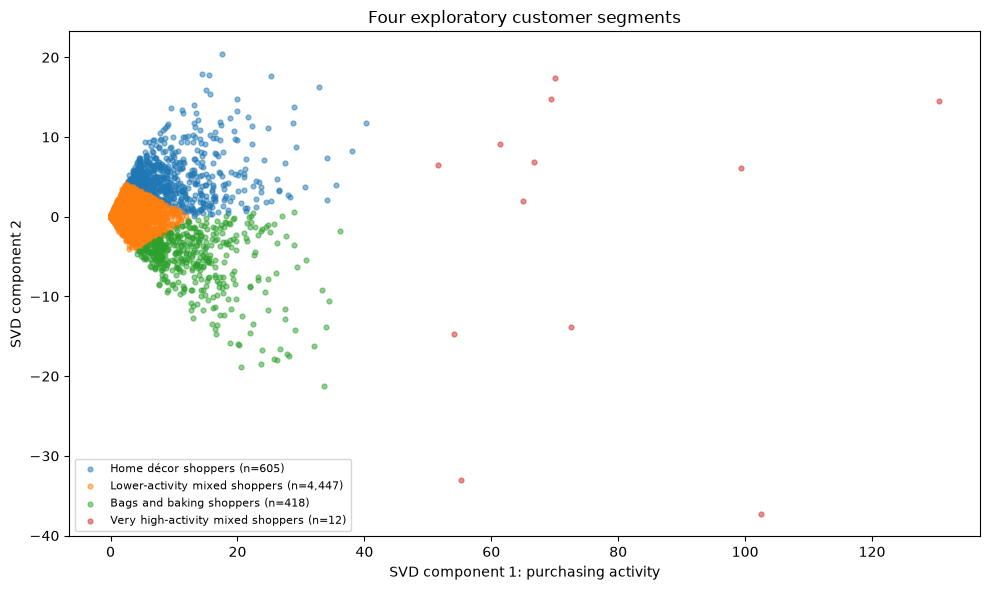

Segment report and both figures saved.


In [51]:
segment_names = {
    0: "Home décor shoppers",
    1: "Lower-activity mixed shoppers",
    2: "Bags and baking shoppers",
    3: "Very high-activity mixed shoppers"
}

reports = project / "reports"
reports.mkdir(exist_ok=True)

segment_summary["Segment"] = segment_summary["Group"].map(
    {group + 1: name for group, name in segment_names.items()}
)

segment_summary.to_csv(
    reports / "customer_segments.csv", index=False
)

figures = project / "figures"
figures.mkdir(exist_ok=True)

# SVD reconstruction-error curve
plt.figure(figsize=(7, 4))
plt.plot(
    svd_results["k"],
    svd_results["Relative reconstruction error"],
    marker="o"
)
plt.xlabel("Number of components (k)")
plt.ylabel("Relative reconstruction error")
plt.title("SVD compression trade-off")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figures / "svd_error_curve.png", dpi=200)
plt.show()

# Named customer segments
plt.figure(figsize=(10, 6))

for group, name in segment_names.items():
    mask = cluster_labels == group
    plt.scatter(
        customer_map[mask, 0],
        customer_map[mask, 1],
        s=12,
        alpha=0.5,
        label=f"{name} (n={mask.sum():,})"
    )

plt.xlabel("SVD component 1: purchasing activity")
plt.ylabel("SVD component 2")
plt.title("Four exploratory customer segments")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(figures / "customer_map.png", dpi=200)
plt.show()

print("Segment report and both figures saved.")

In [52]:
from importlib.metadata import version

packages = [
    "pandas",
    "openpyxl",
    "numpy",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "ipykernel"
]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

(project / "requirements.txt").write_text(requirements)

print(requirements)
print("requirements.txt saved.")

pandas==3.0.6
openpyxl==3.1.5
numpy==2.5.3
scipy==1.18.1
scikit-learn==1.9.1
matplotlib==3.11.2
ipykernel==7.4.0

requirements.txt saved.


## Decision Log

- Cleaning: Removed cancellations, non-positive quantities or prices,
  and missing customer IDs because they do not represent valid
  customer purchases. Excluded charges, adjustments, samples, test
  entries and gift vouchers to focus recommendations on merchandise.
  Kept unusual codes describing real products, including DCGS and PADS.

- Time split: Reserved the final two months for testing to evaluate
  future purchases. Training data alone determined product filtering
  and model fitting.

- Purchase values: Summed quantities for each customer-product pair,
  then applied log(1 + quantity) to reduce the influence of large orders.

- Product filtering: Kept products bought by at least 10 distinct
  training customers to reduce items with limited similarity evidence.

- Main method: Selected truncated SVD before fitting because it works
  directly on sparse purchase data without centering.

- Component count: Tested 10, 20, 50, 100 and 200 components. Selected
  50 as a storage-focused compromise: factors occupy 3.67 MB versus
  5.00 MB for the sparse matrix. Higher tested counts exceed sparse
  storage. The reconstruction curve has no clear elbow.

- Recommendations and evaluation: Used cosine similarity between
  product factors, weighted by customers' log-purchase values.
  Excluded previously purchased products. Compared against products
  ranked by training quantities, using the same eligible test customers.
  Reported coverage separately for excluded customers and products.

- Customer groups: Used four clusters within the required 3–6 range.
  Standardized the first two SVD scores to give both dimensions equal
  weight during clustering. Named groups using their purchase profiles;
  these are exploratory segments influenced by purchasing activity.

- Memory measurement: Measured peak memory in separate processes.
  Figures include imports, matrix loading and fitting, rather than
  only additional memory allocated during fitting.